# 06 · Club goals and transfer plans: replacing several players for a purpose

Notebooks 02–05 answer one question: *"we sell one player, who replaces him?"* Real clubs face a harder version:

1. They often sell **several players in the same window**, with **one shared budget**. Money spent on one position is
   missing for another.
2. They don't always want the same thing. Sometimes the goal is to **make money** (buy young players and sell them later
   for more), sometimes to **strengthen the squad** (get the best possible players, whatever their style), and sometimes
   to **focus on one part of the team** (for example, improve the attack).

This notebook adds both, and, as before, **tests every new idea against a simple alternative before trusting it**:

| New part | What it does | How we test it |
|---|---|---|
| Value-in-2-years model | Predicts a player's market value two seasons ahead | Against "the value stays the same" |
| Stay model | Predicts the chance a player is still in the game in two years | AUC against simple rules, plus calibration |
| Goal "make money" | Ranks by expected resale profit | Backtest: real profit two years later |
| Transfer plan (optimizer) | Several sold players, one budget | Backtest: joint plan vs splitting the budget by hand |
| Focus | Positions in the focus count double | Does the money really move there? |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path("../src").resolve()))
import plot_style
from plot_style import BLUE, ORANGE, AQUA, INK_2, MUTED, EURO, euro
import backtest as bt
from finder import (FOCUS_GROUPS, FUTURE_FEATURES, GOALS, ReplacementFinder, growth_pairs, load_players,
                    train_future_value_model, train_stay_model, with_log_value)

plot_style.apply()
pd.set_option("display.width", 200)
players = load_players()
CACHE = Path("../data/processed")
RECOMPUTE = False   # set to True after changing src/finder.py or src/backtest.py

_finders = {}
def finder_for(version):
    """Build each season's Finder only once (training three models takes ~15 seconds)."""
    if version not in _finders:
        _finders[version] = ReplacementFinder(players, version)
    return _finders[version]

## 1. Two new models

The goal "make money" needs two things the project didn't have before:

- **How much will the player be worth in two years?** A gradient boosting **regression** model predicts log(market value)
  two seasons ahead. It uses the same 45 features as the growth model plus today's log value.
- **Will he still be playing?** About a third of players disappear from the game within two years (notebook 01). A player
  who disappears can't be sold on at a good price. A gradient boosting **classification** model predicts the probability
  that the player is still in the game two years later. This is also one of the task's suggested problems: *"estimate the
  probability that a transfer turns out to be a failure"*.

Both follow the same no-leakage rule as the growth model: they learn only from pairs whose "two years later" is already
known at the decision date. Here we train them for a decision in 2019 (pairs up to FIFA 17 → 19) and test them on
decisions in 2019 and 2020, which they never saw.

From these we compute, for every player: **expected resale = chance he stays × predicted value in 2 years**, and
**expected profit = expected resale − price**.

In [2]:
pairs = with_log_value(growth_pairs(players))
test = pairs[pairs.fifa_version.isin([19, 20]) & (pairs.value_eur > 0)].copy()
value_model = train_future_value_model(players, decision_version=19)
stay_model = train_stay_model(players, decision_version=19)

survivors = test[test.value_eur_2y > 0]
real = np.log(survivors.value_eur_2y)
predicted = value_model.predict(survivors[FUTURE_FEATURES])
print("Value in 2 years: typical error (median, %)")
print(f"  'value stays the same' : {np.median(np.abs(np.exp(survivors.log_value - real) - 1)):.0%}")
print(f"  our model              : {np.median(np.abs(np.exp(predicted - real) - 1)):.0%}")
print(f"  rank correlation of predicted vs real value change: "
      f"{spearmanr(predicted - survivors.log_value, real - survivors.log_value).statistic:.2f}")

stayed = test.overall_2y.notna()
p_stay = stay_model.predict_proba(test[FUTURE_FEATURES])[:, 1]
print("\nStill in the game in 2 years: AUC (0.5 = coin flip, 1 = perfect)")
print(f"  rule 'better players stay' (rating only) : {roc_auc_score(stayed, test.overall):.2f}")
print(f"  rule 'younger players stay' (age only)   : {roc_auc_score(stayed, -test.age):.2f}")
print(f"  our model                                : {roc_auc_score(stayed, p_stay):.2f}")

Value in 2 years: typical error (median, %)
  'value stays the same' : 50%
  our model              : 39%
  rank correlation of predicted vs real value change: 0.70



Still in the game in 2 years: AUC (0.5 = coin flip, 1 = perfect)
  rule 'better players stay' (rating only) : 0.69
  rule 'younger players stay' (age only)   : 0.53
  our model                                : 0.78


**AUC** answers: if we take one player who stayed and one who disappeared, how often does the model give the stayer the
higher probability? 0.5 is a coin flip, 1 is perfect.

Both models clearly beat the simple rules. Market values are hard to predict two years ahead: the value model's typical
error is still 39%. But that's well below the 50% of "the value stays the same", and it ranks *who will gain value* well
(rank correlation 0.70).

A probability is only useful if it means what it says. If the model says "70%", about 70% of those players should
really stay. This is called **calibration**. Let's check it: we split players into five groups by predicted probability
and compare with what really happened.

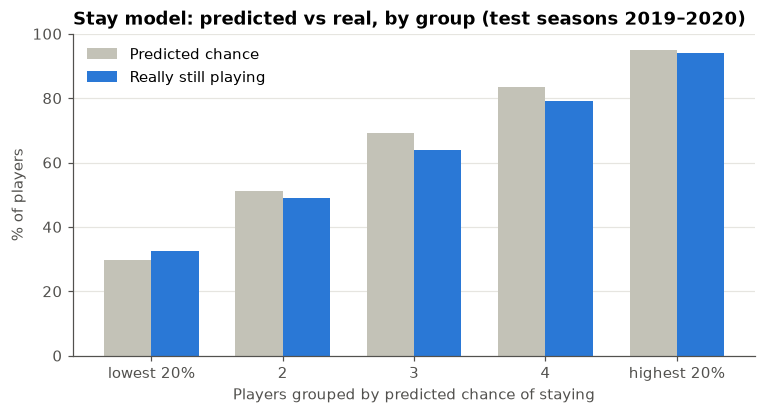

,predicted,real
lowest 20%,0.30,0.32
2,0.51,0.49
3,0.69,0.64
4,0.84,0.79
highest 20%,0.95,0.94


In [3]:
groups = pd.qcut(p_stay, 5, labels=["lowest 20%", "2", "3", "4", "highest 20%"])
calib = pd.DataFrame({"predicted": pd.Series(p_stay).groupby(groups.codes).mean().to_numpy(),
                      "real": stayed.groupby(groups.codes).mean().to_numpy()}, index=groups.categories)

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(calib))
ax.bar(x - 0.18, calib.predicted * 100, width=0.36, color=MUTED, label="Predicted chance")
ax.bar(x + 0.18, calib.real * 100, width=0.36, color=BLUE, label="Really still playing")
ax.set_xticks(x, calib.index)
ax.set(title="Stay model: predicted vs real, by group (test seasons 2019–2020)",
       xlabel="Players grouped by predicted chance of staying", ylabel="% of players", ylim=(0, 100))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.show()
calib.round(2)

The two bars are close in every group, so the probabilities can be read at face value. In the riskiest fifth, only about
a third of players are still in the game two years later; in the safest fifth, almost all are. The Finder now shows this
probability for every candidate, and adds a **"high drop-out risk"** flag below 50%.

## 2. The goal "make money": does it really earn money?

The profit mode ranks candidates by **expected profit**. We test it with the same 750-case backtest as notebook 04
(same sold players, same budgets, same candidate pools), and measure the **real profit** of each pick: his market value
two seasons later minus the price.

We are deliberately strict: **a player who left the game counts as resold for €0**, so his whole price is lost.

In [4]:
PROFIT_CACHE = CACHE / "backtest_profit.parquet"
if PROFIT_CACHE.exists() and not RECOMPUTE:
    picks = pd.read_parquet(PROFIT_CACHE)
else:
    systems = {k: bt.SYSTEMS[k] for k in [bt.FINDER, "Highest overall", "Highest potential", "Random"]}
    systems["Make money (expected profit)"] = bt.pick_most_profit
    picks = bt.run_backtest(players, (19, 20, 21), 250, systems=systems,
                            finders={v: finder_for(v) for v in (19, 20, 21)})
    picks.to_parquet(PROFIT_CACHE)

picks["profit_m"] = bt.realized_profit(picks)
order = ["Make money (expected profit)", "Highest potential", bt.FINDER, "Highest overall", "Random"]
per_case = picks.groupby(["system", "case"]).agg(
    profit=("profit_m", "mean"), success=("success", "mean"),
    dropout=("still_in_game", lambda s: 1 - s.mean()), price=("value_eur", lambda v: v.mean() / 1e6),
    age=("age", "mean"))
summary = per_case.groupby("system").mean().loc[order]
summary.style.format({"profit": "€{:+.2f}M", "success": "{:.1%}", "dropout": "{:.1%}", "price": "€{:.2f}M", "age": "{:.1f}"})

,profit,success,dropout,price,age
system,,,,,
Make money (expected profit),€+5.45M,49.0%,5.4%,€2.75M,18.2
Highest potential,€+5.29M,43.9%,7.0%,€2.58M,17.7
Finder (style filter + growth model),€+2.80M,56.1%,13.1%,€3.83M,21.9
Highest overall,€-1.11M,42.9%,19.9%,€3.87M,27.2
Random,€+0.13M,11.1%,31.9%,€1.42M,23.6


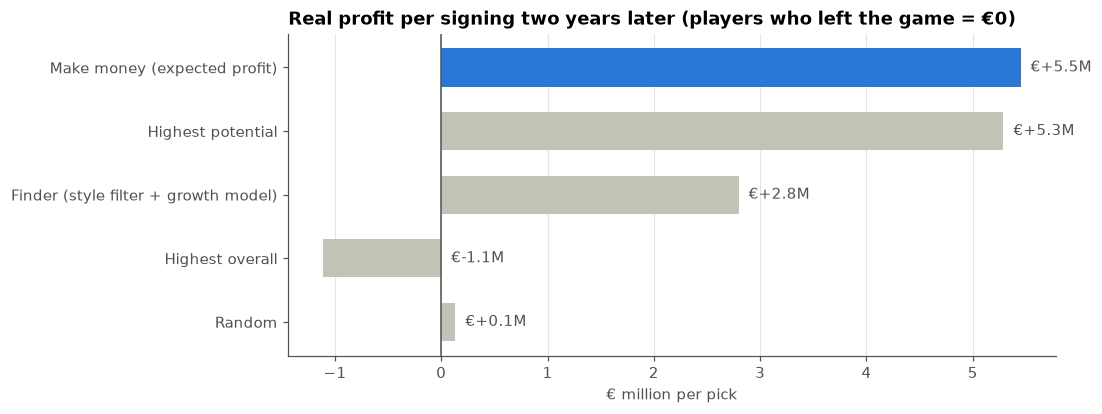

Make money vs Highest potential, profit €M  : +0.16  [-0.13, +0.44]
Make money vs Finder (like-for-like), €M   : +2.65  [+2.34, +2.94]
Make money vs Highest potential, success   : +0.05  [+0.03, +0.07]


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
names = summary.index[::-1]
colors = [BLUE if n.startswith("Make money") else MUTED for n in names]
ax.barh(names, summary.profit[names], color=colors, height=0.6)
ax.axvline(0, color=INK_2, lw=1)
for n in names:
    v = summary.profit[n]
    ax.text(max(v, 0), n, f"  €{v:+.1f}M", va="center", ha="left", color=INK_2)
ax.grid(axis="y", visible=False)
ax.set(title="Real profit per signing two years later (players who left the game = €0)", xlabel="€ million per pick")
plt.show()

def boot(a, b, metric="profit", n=2000):
    d = (per_case[metric].unstack(0)[a] - per_case[metric].unstack(0)[b]).to_numpy()
    r = np.random.default_rng(0).choice(d, (n, len(d))).mean(1)
    return f"{d.mean():+.2f}  [{np.percentile(r, 2.5):+.2f}, {np.percentile(r, 97.5):+.2f}]"
print("Make money vs Highest potential, profit €M  :", boot("Make money (expected profit)", "Highest potential"))
print("Make money vs Finder (like-for-like), €M   :", boot("Make money (expected profit)", bt.FINDER))
print("Make money vs Highest potential, success   :", boot("Make money (expected profit)", "Highest potential", "success"))

Read this carefully, because the answer is mixed:

- **The profit mode really earns money:** about €5.5M per signing two years later, even with the strict rule that a
  player who disappears is worth nothing. Buying the best current rating *loses* money: those players are at their peak.
- **But it does not beat the simple rule "buy the highest potential" on money.** The difference is small and its 95%
  interval includes zero. Both strategies buy very young players (average age about 18), and EA's potential already
  captures most of their future value.
- **Where it does win:** its signings are better *replacements* (49% success against 44%, a difference of +5 points with
  a 95% interval of +3 to +7) and fewer of them disappear from the game (5% against 7%). The stay model steers it away
  from young players who never make it.

So the honest conclusion is: **for pure profit, our model is as good as the best simple rule, not better; but it earns
that money with players who are more useful to the team in the meantime.** This is the kind of negative-ish result the task
explicitly values, and it tells a club which tool to trust for which job.

### A real example: making money with Bissouma's replacement (summer 2022)

Let's ask the profit mode for Brighton's Bissouma case with a €25M budget, and look at what happened by January 2023:

In [6]:
f22 = finder_for(22)
s22 = f22.season
bissouma = s22[(s22.short_name == "Y. Bissouma") & (s22.club_name == "Brighton & Hove Albion")].iloc[0]
rec = f22.recommend(bissouma.player_id, budget=25e6, n=5, goal="profit", wage_cap=bissouma.wage_eur,
                    max_age=27, min_overall=bissouma.overall - 12)
fifa23 = players[players.fifa_version == 23].set_index("player_id")
view = rec[["short_name", "age", "club_name", "overall", "value_eur", "pred_value_2y", "p_stay", "expected_profit"]].copy()
view["value Jan 2023"] = view.index.map(fifa23.value_eur)
view["club Jan 2023"] = view.index.map(fifa23.club_name)
view.style.format({"value_eur": euro, "pred_value_2y": euro, "expected_profit": euro, "value Jan 2023": euro,
                   "p_stay": "{:.0%}", "age": "{:.0f}", "overall": "{:.0f}"})

,short_name,age,club_name,overall,value_eur,pred_value_2y,p_stay,expected_profit,value Jan 2023,club Jan 2023
player_id,,,,,,,,,,
257057,A. Onana,19,Lille,73,€6M,€14.5M,99%,€8.33M,€11.5M,Everton
247090,E. Fernández,20,River Plate,77,€23M,€29M,99%,€5.75M,€42.5M,Benfica
257271,L. Gourna,17,Saint-Étienne,71,€3.6M,€9.26M,99%,€5.55M,€4.6M,Salzburg
252027,A. Vranckx,18,VfL Wolfsburg,72,€5.5M,€10.6M,99%,€5.02M,€6.5M,Milan
253306,M. Ugarte,20,Sporting CP,74,€9M,€13.6M,98%,€4.41M,€28.5M,Sporting CP


Half a season is too early to judge a two-year prediction, but the direction is already visible: **all five players were
worth more in January 2023** than in summer 2022. Enzo Fernández went from €23M to €42.5M, and Manuel Ugarte from €9M to
€28.5M. (A real-world note: Chelsea bought Enzo Fernández in January 2023 for a reported fee of more than €100M. EA's
value, a formula, reacts far more slowly than the real market.) This is one hand-picked case, not proof; the 750-case
table above is the evidence.

## 3. Transfer plans: several players, one budget

When a club sells several players, it has one budget for all the replacements. The simple way to handle that is to
**split the budget by hand**: give each sold player his own share (60% of his own value) and choose each replacement
separately. The problem is that money can't move between positions. If a great player costs a bit more than one share,
and a cheap one is enough for the other position, the simple method can't see it.

Our **transfer plan** solves the whole problem at once with **integer programming** (scipy's `milp`):

- one variable per (sold player, candidate): 1 = buy, 0 = don't;
- **exactly one** signing for every sold player;
- **never the same candidate twice** (two sold centre-backs can't both be replaced by the same player);
- **total price ≤ budget**;
- maximize the sum of the goal's gains (for like-for-like: predicted rating in 2 years minus the sold player's rating).

For every sold player the optimizer considers the best options *and* every "best for its price" option (nobody cheaper has
a higher gain). That makes it mathematically impossible for the joint plan to do worse than splitting the budget by hand,
on predictions. The backtest checks whether that also holds in **reality**.

The backtest: at the end of 2019, 2020 and 2021, 150 random clubs each sell **2** (or **3**) established players at once.
Both methods get the same total budget (60% of the sold players' total value), the same candidates and the same limits.

In [7]:
plan_results = {}
for k in (2, 3):
    path = CACHE / f"plan_backtest_k{k}.parquet"
    if path.exists() and not RECOMPUTE:
        pp = pd.read_parquet(path)
    else:
        pp = bt.run_plan_backtest(players, (19, 20, 21), 150, k=k, finders={v: finder_for(v) for v in (19, 20, 21)})
        pp.to_parquet(path)
    per = pp.groupby(["method", "case"]).agg(
        success=("success", "mean"), predicted=("pred_overall_2y", "mean"),
        used=("value_eur", "sum"), budget=("budget", "first"),
        dropout=("still_in_game", lambda s: 1 - s.mean()))
    per["used"] = per.used / per.budget
    plan_results[k] = per

rows = []
for k, per in plan_results.items():
    for method, r in per.groupby("method").mean().iterrows():
        rows.append({"players sold": k, "method": method, "success": r.success, "predicted rating in 2y": r.predicted,
                     "budget used": r.used, "dropped out": r.dropout, "cases": per.loc[method].shape[0]})
pd.DataFrame(rows).style.format({"success": "{:.1%}", "predicted rating in 2y": "{:.1f}", "budget used": "{:.0%}",
                                 "dropped out": "{:.1%}"}).hide(axis="index")

players sold,method,success,predicted rating in 2y,budget used,dropped out,cases
2,Joint plan (optimizer),64.8%,72.7,96%,11.0%,450
2,"Split budget, choose separately",60.6%,72.1,90%,13.8%,450
3,Joint plan (optimizer),66.6%,73.3,98%,9.0%,450
3,"Split budget, choose separately",59.7%,72.4,89%,11.8%,450


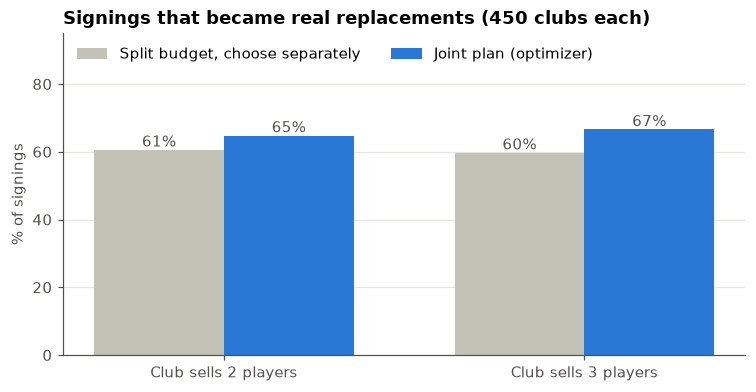

k=2  joint − split, success  : +0.042  95% [+0.009, +0.077]   cases where the joint plan predicted worse: -
k=2  joint − split, predicted: +0.588  95% [+0.544, +0.632]   cases where the joint plan predicted worse: 0
k=3  joint − split, success  : +0.069  95% [+0.038, +0.100]   cases where the joint plan predicted worse: -
k=3  joint − split, predicted: +0.866  95% [+0.821, +0.912]   cases where the joint plan predicted worse: 0


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(2)
for i, (method, color) in enumerate([("Split budget, choose separately", MUTED), ("Joint plan (optimizer)", BLUE)]):
    vals = [plan_results[k].loc[method].success.mean() * 100 for k in (2, 3)]
    ax.bar(x + (i - 0.5) * 0.36, vals, width=0.36, color=color, label=method)
    for xi, v in zip(x, vals):
        ax.text(xi + (i - 0.5) * 0.36, v + 1, f"{v:.0f}%", ha="center", color=INK_2)
ax.set_xticks(x, ["Club sells 2 players", "Club sells 3 players"])
ax.set(title="Signings that became real replacements (450 clubs each)", ylabel="% of signings", ylim=(0, 95))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
plt.show()

for k, per in plan_results.items():
    for metric in ("success", "predicted"):
        d = (per[metric].unstack(0)["Joint plan (optimizer)"] - per[metric].unstack(0)["Split budget, choose separately"]).to_numpy()
        r = np.random.default_rng(0).choice(d, (2000, len(d))).mean(1)
        worse = (d < -1e-9).sum() if metric == "predicted" else "-"
        print(f"k={k}  joint − split, {metric:9s}: {d.mean():+.3f}  95% [{np.percentile(r, 2.5):+.3f}, {np.percentile(r, 97.5):+.3f}]"
              f"   cases where the joint plan predicted worse: {worse}")

**The joint plan wins, and the advantage grows with the number of players sold.** With two players sold, its signings
become real replacements about 4 percentage points more often; with three, about 7 points more often. Both 95% intervals
are entirely above zero. On predictions it is never worse in a single case, as the mathematics promises.

Why does it win? Look at "budget used": the hand-split method leaves about 10% of the money unspent, because each share
is a hard wall. The optimizer moves money to where it buys the most: for example, it spends a bit more on a position where a
much better player is just out of reach, and saves on a position where a cheap player is almost as good.

An honest note on our process: our **first version of the optimizer lost** to the simple method. It only considered the
25 best options per player, so cheap good players were sometimes missing, and its style filter was computed on a different
pool. The backtest revealed it: its *predicted* quality was lower than the simple method's, which an optimizer should never
allow. After the fix (the "best for its price" options and the same pool for both methods) the result above appeared.

## 4. Focus: does the money really move?

A club can say "this summer we want to improve the **attack**" (or the midfield, or the defense). In the plan, the gain of
the focus positions counts **double** (`FOCUS_WEIGHT = 2`), so the optimizer is willing to spend more there.

This is a **preference**, not a prediction, so there is nothing to "test" against reality. What we can check is that the
setting does what it promises. Here is Brighton's real summer 2022: they sold Bissouma (defensive midfielder) and
Cucurella (left-back). Budget €45M:

In [9]:
cucurella = s22[(s22.short_name == "Cucurella") & (s22.club_name == "Brighton & Hove Albion")].iloc[0]
sold_ids = [bissouma.player_id, cucurella.player_id]
rows = []
for focus in [None, "midfield", "defense"]:
    plan = f22.plan(sold_ids, budget=45e6, focus=focus)
    for _, r in plan.iterrows():
        rows.append({"focus": focus or "none", "replaces": r.sold_short_name, "signing": r.short_name,
                     "age": r.age, "price": r.value_eur, "rated now": r.overall, "predicted in 2y": r.pred_overall_2y})
focus_table = pd.DataFrame(rows)
focus_table.style.format({"price": euro, "age": "{:.0f}", "rated now": "{:.0f}", "predicted in 2y": "{:.1f}"}).hide(axis="index")

focus,replaces,signing,age,price,rated now,predicted in 2y
none,Y. Bissouma,N. Maksimović,26,€20.5M,79,79.0
none,Cucurella,D. Raum,23,€23.5M,79,79.2
midfield,Y. Bissouma,I. Bennacer,23,€33.5M,81,80.9
midfield,Cucurella,T. Livramento,18,€8.5M,74,76.9
defense,Y. Bissouma,J. Bellegarde,23,€8.5M,75,75.1
defense,Cucurella,Renan Lodi,23,€36.5M,81,81.9


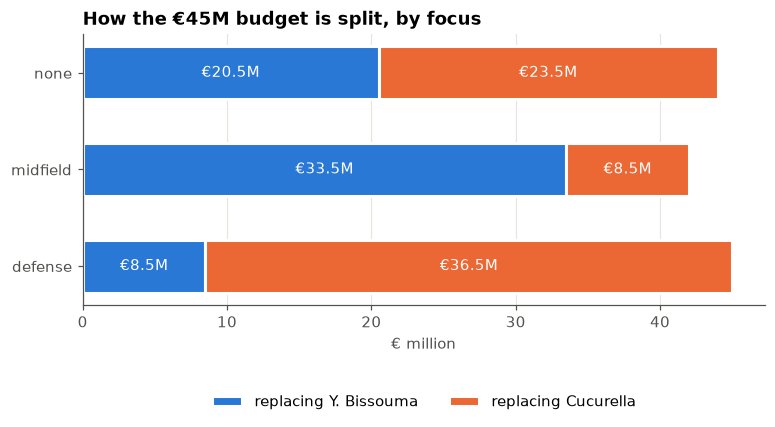

In [10]:
spend = focus_table.pivot(index="focus", columns="replaces", values="price").loc[["none", "midfield", "defense"]] / 1e6
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(spend))
for col, color in zip(["Y. Bissouma", "Cucurella"], [BLUE, ORANGE]):
    ax.barh(spend.index, spend[col], left=left, color=color, height=0.55, label=f"replacing {col}",
            edgecolor="white", linewidth=2)
    for i, (l, v) in enumerate(zip(left, spend[col])):
        ax.text(l + v / 2, i, f"€{v:.1f}M", ha="center", va="center", color="white", fontsize=10)
    left += spend[col].to_numpy()
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(title="How the €45M budget is split, by focus", xlabel="€ million")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
plt.show()

Without a focus, the money is split roughly evenly (€20.5M and €23.5M). With **focus on midfield**, the plan spends
€33.5M on Bissouma's position (Ismaël Bennacer, rated 81) and fills left-back with an €8.5M 18-year-old. With **focus on
defense** it does the opposite: €36.5M on a left-back (Renan Lodi, rated 81) and €8.5M in midfield. The setting does exactly what a sporting director would expect. Whether it's the *right* strategy
is a club decision, not a statistical one.

## 5. Limits of the new features

| Limitation | What it means |
|---|---|
| Profit is measured in EA values | Real transfer fees react differently (Enzo Fernández: a reported €100M+ in January 2023). Profit numbers are a guide, not a promise |
| Profit mode ties with "highest potential" on money | For pure resale, our model isn't better than the best simple rule; its advantage is better replacements and fewer drop-outs |
| The focus weight (×2) is a choice, not learned | A different weight moves the money more or less. It expresses the club's wish; there's no "correct" value to fit |
| One signing per sold player | The plan doesn't decide *not* to replace someone, or to buy two players for one position |
| No full-squad view | Squad depth, total wage bill and the starting eleven are not modelled. Planning the whole squad is the next step |

## Summary

| New part | Result | Verdict |
|---|---|---|
| Value-in-2-years model | Typical error clearly below "value stays the same"; ranks value changes well | Used in profit mode |
| Stay model | AUC about 0.78 vs 0.69 (rating only); well calibrated | Used in profit mode and as a risk flag |
| Goal "make money" | ≈ €5.5M real profit per signing; ties "highest potential" on money, better replacements (49% vs 44%) and fewer drop-outs | Useful, honestly no better than the best simple rule on money alone |
| Transfer plan (optimizer) | +4 points (2 players) and +7 points (3 players) over splitting the budget, both significant | Clear win, grows with the number of players |
| Focus | Moves the budget to the focus positions as intended | Works as designed; a club preference, not a prediction |